https://www.kaggle.com/c/pneumonia-sai3

In [1]:
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
import os
from glob import glob
from tqdm.auto import tqdm
import torch
import torch.nn as nn
import torchvision
from sklearn.model_selection import train_test_split
import pandas as pd

#### Prepare dataset


In [2]:
IMG_SIZE = 256
BATCH_SIZE = 64

In [3]:
# read all paths
img_paths_all = glob('../data/pneumonia-kaggle/train/*/*.jpeg')
img_paths_test = sorted(glob('../data/pneumonia-kaggle/test/*.jpeg'))
img_paths_train, img_paths_val = train_test_split(
    img_paths_all,
    test_size=0.2
)

In [4]:
# number of images
len(img_paths_train), len(img_paths_val), len(img_paths_test)

(4172, 1044, 624)

../data/pneumonia-kaggle/train/PNEUMONIA/person24_bacteria_112.jpeg (256, 256)


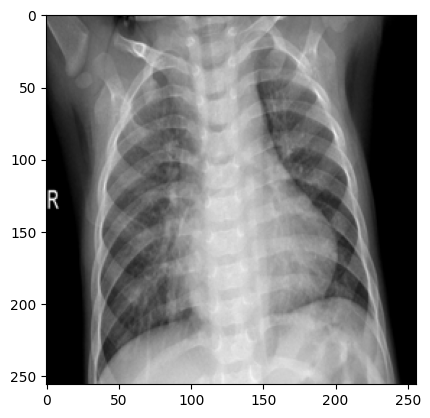

In [6]:
# show image
path = img_paths_train[0]
img = Image.open(path).convert("RGB").resize((IMG_SIZE, IMG_SIZE))
print(path, img.size)
plt.imshow(img)
plt.show()

In [7]:
# Extract img class
img_path = img_paths_train[0]
print(img_path)
# read label
folder = img_path.split(os.sep)[-2]
print(folder)

if folder == 'NORMAL':
    label = 0
else:
    label = 1

label

../data/pneumonia-kaggle/train/PNEUMONIA/person24_bacteria_112.jpeg
PNEUMONIA


1

Dataset, Dataloader

In [8]:
class PneumoniaDataset(torch.utils.data.Dataset):
    def __init__(self, paths, transform):
        self.paths = paths
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        path = self.paths[idx]
        img = Image.open(path).convert("RGB")
        img = self.transform(img)

        # read label
        folder = path.split(os.sep)[-2]
        label = 0 if folder == 'NORMAL' else 1
        label = torch.tensor(label, dtype=torch.long)

        return img, label

In [ ]:
transforms = TODO

train_ds = PneumoniaDataset(img_paths_train, transforms)
val_ds = PneumoniaDataset(img_paths_val, transforms)

In [ ]:
img, label = train_ds[2]
print(img.shape, label)
plt.imshow(img.permute(1, 2, 0))
plt.show()

In [ ]:
BS = 32
train_loader = torch.utils.data.DataLoader(train_ds, BS, shuffle=True)
val_loader = torch.utils.data.DataLoader(val_ds, BS)

#### Build model

#### ViT 結構練習

In [13]:
import torch 
from torch import nn
from einops.layers.torch import Rearrange

class PatchEmbedding(nn.Module):
    """把 (B, C, H, W) 影像切成 patch,攤平後線性投影成 (B, N, dim) 的 token 序列。"""
    def __init__(self, image_size, patch_size, channels, dim):
        super().__init__()
        # 提示:
        #   1. 一張圖會切出幾個 patch? num_patches = (image_size // patch_size) ** 2
        #   2. 每個 patch 攤平後的維度? patch_dim = channels * patch_size * patch_size
        #   3. 用 einops 的 Rearrange 把
        #        (b, c, (h p1), (w p2)) -> (b, (h w), (p1 p2 c))
        #      其中 p1 = p2 = patch_size
        #   4. 再接一層 nn.Linear(patch_dim, dim) 投影到模型維度

        num_patches = (image_size // patch_size) ** 2
        patch_dim = patch_size * patch_size * channels 
        # 每個patch轉換前的dim
        self.to_embedding = nn.Sequential(
        #(batch, channel, H, W)   ->       # (batch, num_patches, patch_dim)
        Rearrange('b c (h p1) (w p2) -> b (h w) (p1 p2 c)', p1=patch_size, p2=patch_size),
        nn.Linear(patch_dim, dim), # 單個patch裡面的dimension 轉換
        )

    def forward(self, x):
        return self.to_embedding(x)

# === Shape 測試:寫完上面就跑這段 ===
x = torch.randn(2, 3, 224, 224)        # batch=2, 3 通道, 224x224 的圖
pe = PatchEmbedding(image_size=224, patch_size=16, channels=3, dim=128)
out = pe(x)
print("輸出 shape:", out.shape)         # 期望 torch.Size([2, 196, 128])
assert out.shape == (2, 196, 128), "shape 不對,回去檢查 Rearrange 的維度!"
print("✅ PatchEmbeddig")

class FeedForward(nn.Module):
    def __init__(self, dim, hidden_dim, dropout=0.):
        super().__init__()
        self.net = nn.Sequential(
            nn.LayerNorm(dim),
            nn.Linear(dim, hidden_dim),
            nn.GELU(),
            nn.Linear(hidden_dim, dim)
        )
    def forward(self, x):
        return self.net(x)
# === Shape 測試 ===
x = torch.randn(2, 196, 128)            # 接續 PatchEmbedding 的輸出
ff = FeedForward(dim=128, hidden_dim=512)
out = ff(x)
print(out.shape)                        # 期望 torch.Size([2, 196, 128])
assert out.shape == x.shape, "FeedForward 進出 shape 必須一樣!"
print("✅ FeedForward 過關!")

輸出 shape: torch.Size([2, 196, 128])
✅ PatchEmbeddig
torch.Size([2, 196, 128])
✅ FeedForward 過關!


In [14]:
## Attention
class SelfAttention(nn.Module):
    def __init__(self, dim, dim_head=64):
        super().__init__()
        self.scale = dim_head ** -0.5
        self.norm = nn.LayerNorm(dim) 

        self.W_q = nn.Linear(dim, dim_head, bias=False)
        self.W_k = nn.Linear(dim, dim_head, bias=False)
        self.W_v = nn.Linear(dim, dim_head, bias=False)
        self.to_out = nn.Linear(dim_head, dim)

    def forward(self, x):
        x = self.norm(x)
        q = self.W_q(x)
        k = self.W_k(x)
        v = self.W_v(x)

        attention_matrix = torch.matmul(q, k.transpose(-1, -2)) * self.scale
        weighted_value = torch.matmul(torch.softmax(attention_matrix, dim=-1), v)
        return self.to_out(weighted_value)

x = torch.randn(2, 196, 128)
sa = SelfAttention(dim=128, dim_head=64)
out = sa(x)
print(out.shape)          # 期望 (2, 196, 128)
assert out.shape == x.shape
print("✅ SelfAttention 過關!")


torch.Size([2, 196, 128])
✅ SelfAttention 過關!


In [18]:
from einops import rearrange
class MultiHeadAttention(nn.Module):
    def __init__(self, dim, heads = 8, dim_head = 64):
        super().__init__()
        self.heads = heads
        inner_dim = heads * dim_head
        self.scale = dim_head ** -0.5
        self.norm = nn.LayerNorm(dim)
        self.W_q = nn.Linear(dim, inner_dim, bias=False)
        self.W_k = nn.Linear(dim, inner_dim, bias=False)
        self.W_v = nn.Linear(dim, inner_dim, bias=False)
        self.to_out = nn.Linear(inner_dim, dim)

    def forward(self, x):
        x = self.norm(x)
        q = self.W_q(x)
        k = self.W_k(x)
        v = self.W_v(x)
        q = rearrange(q, 'B token (head dim_per_head) -> B head token dim_per_head', head=self.heads)
        k = rearrange(k, 'B token (head dim_per_head) -> B head token dim_per_head', head=self.heads)
        v = rearrange(v, 'B token (head dim_per_head) -> B head token dim_per_head', head=self.heads)

        attention_matrix = torch.matmul(q, k.transpose(-1, -2) * self.scale)
        attn = attention_matrix.softmax(dim=-1)
        out = torch.matmul(attn, v)

        out = rearrange(out, 'B head token dim_per_head -> B token (head dim_per_head)')
        return self.to_out(out)
    
x = torch.randn(2, 196, 128)
mha = MultiHeadAttention(dim=128, heads=8, dim_head=64)
out = mha(x)
print(out.shape)          # 期望 (2, 196, 128)
assert out.shape == x.shape
print("✅ MultiHeadAttention 過關!")

torch.Size([2, 196, 128])
✅ MultiHeadAttention 過關!


In [ ]:
model = TODO

inputs = torch.randn(1, 3, 224, 224)
outputs = model(inputs)
outputs.shape

#### Training

In [ ]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [ ]:
model = model.to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-4,
)

In [ ]:
from sklearn.metrics import (
    roc_curve,
    auc,
)

def train(dataloader, model, loss_fn, optimizer):
    size = len(dataloader.dataset)
    num_batches = len(dataloader)

    model.train() # to training mode.
    epoch_loss, epoch_correct = 0, 0
    y_preds = []
    y_trues = []
    for x, y in tqdm(dataloader, leave=False):
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        pred = model(x)
        loss = loss_fn(pred, y)
        loss.backward()
        optimizer.step()
        # write to logs
        epoch_loss += loss.item() # tensor -> python value
        # (N, Class)
        epoch_correct += (pred.argmax(dim=1) == y).sum().item()

        pred_probs = nn.functional.softmax(pred, dim=1) # apply softmax to logits
        y_preds.append(pred_probs[:, 1]) # target class : 1
        y_trues.append(y)

    # Compute AUROC
    y_preds = torch.cat(y_preds).detach().cpu()
    y_trues = torch.cat(y_trues).detach().cpu()
    fp_rate, tp_rate, threshold = roc_curve(
        y_trues, y_preds
    )
    auc_score = auc(fp_rate, tp_rate)

    return epoch_loss/num_batches, epoch_correct/size, auc_score


def test(dataloader, model, loss_fn):
    size = len(dataloader.dataset) # number of samples
    num_batches = len(dataloader) # batches per epoch

    model.eval() # model to test mode.
    epoch_loss, epoch_correct = 0, 0
    y_preds = []
    y_trues = []
    # No gradient for test data
    with torch.no_grad():
        for x, y in tqdm(dataloader):
            x, y = x.to(device), y.to(device)

            # Compute prediction loss
            pred = model(x)
            loss = loss_fn(pred, y)

            # write to logs
            epoch_loss += loss.item()
            epoch_correct += (pred.argmax(1) == y).sum().item()

            pred_probs = nn.functional.softmax(pred, dim=1) # apply softmax to logits
            y_preds.append(pred_probs[:, 1]) # target class : 1
            y_trues.append(y)
    # Compute AUROC
    y_preds = torch.cat(y_preds).detach().cpu()
    y_trues = torch.cat(y_trues).detach().cpu()
    fp_rate, tp_rate, threshold = roc_curve(
        y_trues, y_preds
    )
    auc_score = auc(fp_rate, tp_rate)
    return epoch_loss/num_batches, epoch_correct/size, auc_score

EPOCHS = 100
logs = {
    'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': [],
    'train_auc': [], 'val_auc': []
}
# Earlystopping
patience = 5
counter = 0
best_loss = np.inf

for epoch in tqdm(range(EPOCHS)):
    train_loss, train_acc, train_auc = train(train_loader, model, loss_fn, optimizer)
    val_loss, val_acc, val_auc = test(val_loader, model, loss_fn)

    print(f'EPOCH: {epoch:04d} \
    train_loss: {train_loss:.4f} val_loss: {val_loss:.4f} \
    train_auc: {train_auc:.3f}, val_auc: {val_auc:3f}')

    logs['train_loss'].append(train_loss)
    logs['train_acc'].append(train_acc)
    logs['train_auc'].append(train_auc)
    logs['val_loss'].append(val_loss)
    logs['val_acc'].append(val_acc)
    logs['val_auc'].append(val_auc)


    torch.save(model.state_dict(), "last.pth")
    # chcek improvement
    if val_loss < best_loss:
        counter = 0
        best_loss = val_loss
        torch.save(model.state_dict(), "best.pth")
    else:
        counter += 1
    if counter >= patience:
        print("Earlystop!")
        break

#### Make Kaggle Submission

https://www.kaggle.com/c/pneumonia-sai3

In [ ]:
class TestDataset(torch.utils.data.Dataset):
    def __init__(self, paths, transform):
        self.paths = paths
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        path = self.paths[idx]
        img = Image.open(path).convert("RGB")
        img = self.transform(img)
        return img

test_paths = sorted(glob('../data/pneumonia-kaggle/test/*.jpeg'))
transforms =
test_ds = TestDataset(test_paths, transforms)
test_loader = torch.utils.data.DataLoader(test_ds, BS)

In [ ]:
model.load_state_dict(torch.load('best.pth'))
_ = model.eval().to(device)

In [ ]:
# Inference
y_pred = []
with torch.no_grad():
    for x in tqdm(test_loader):
        x = x.to(device)
        pred = model(x)
        pred_prob = nn.functional.softmax(pred, dim=1)
        y_pred.append(pred_prob[:, 1]) # class 1 的機率值

y_pred = torch.cat(y_pred, dim=0).cpu().numpy()

In [ ]:
df = pd.DataFrame()
df['Id'] = [f'{i:05d}.jpeg' for i in range(len(img_paths_test))]
df['Category'] = y_pred
df.to_csv('submission.csv', index=None)
df